In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
class AgentState(TypedDict):
    op1: int
    op2: int
    operation: str
    result: int

In [3]:
def add(state: AgentState) -> AgentState:
    state['result'] = state['op1'] + state['op2']
    return state

def sub(state: AgentState) -> AgentState:
    state['result'] = state['op1'] - state['op2']
    return state

def check_operation(state: AgentState):
    if state['operation'] == '+':
        return 'add_node'
    return 'sub_node'

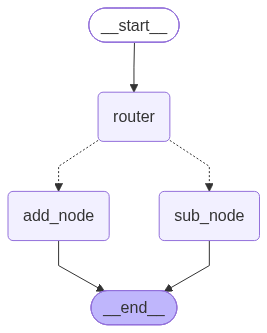

In [4]:
graph = StateGraph(AgentState)

graph.add_node('add_node', add)
graph.add_node('sub_node', sub)
graph.add_node('router', lambda state:state)

graph.add_edge(START, 'router')

graph.add_conditional_edges('router', check_operation, {
    'add_node': 'add_node',
    'sub_node': 'sub_node'
})

graph.add_edge('add_node', END)
graph.add_edge('sub_node', END)

workflow = graph.compile()

workflow

In [5]:
workflow.invoke({'op1': 2, 'op2': 2, 'operation': '+'})

{'op1': 2, 'op2': 2, 'operation': '+', 'result': 4}